In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(r"C:\Users\mohan\OneDrive\Desktop\Python_NareshIt\FSDS-GenAI-AgenticAI\02_Data_Analysis\06_Data_Cleaning_And_Visualization\employee_raw_data.xlsx")

In [3]:
df

,Employee_ID,Employee_Name,Age,Salary,Location
0,101,Aarav^Sharma,28.0,45000.0,Pune
1,102,Mira&Patel,31.0,52000.0,Mumbai
2,103,Rohan^Mehta,NaN,61000.0,Bengaluru
3,104,Sana&Khan,26.0,NaN,Hyderabad
4,105,Ishaan^Verma,35.0,72000.0,NaN
5,106,Diya&Nair,29.0,48000.0,Chennai
6,107,Kabir^Joshi,NaN,55000.0,Pune
7,108,Anaya&Reddy,24.0,NaN,Delhi
8,109,Vivaan^Gupta,32.0,68000.0,NaN
9,110,Ira&Desai,27.0,43000.0,Ahmedabad


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Employee_ID    20 non-null     int64  
 1   Employee_Name  20 non-null     str    
 2   Age            15 non-null     float64
 3   Salary         15 non-null     float64
 4   Location       15 non-null     str    
dtypes: float64(2), int64(1), str(2)
memory usage: 1.2 KB


In [5]:
df.head()

,Employee_ID,Employee_Name,Age,Salary,Location
0,101,Aarav^Sharma,28.0,45000.0,Pune
1,102,Mira&Patel,31.0,52000.0,Mumbai
2,103,Rohan^Mehta,NaN,61000.0,Bengaluru
3,104,Sana&Khan,26.0,NaN,Hyderabad
4,105,Ishaan^Verma,35.0,72000.0,NaN


In [6]:
df.tail()

,Employee_ID,Employee_Name,Age,Salary,Location
15,116,Kiara&Chopra,28.0,51000.0,NaN
16,117,Atharv^Mishra,33.0,64000.0,Lucknow
17,118,Navya&Menon,25.0,NaN,Kochi
18,119,Dhruv^Bose,NaN,57000.0,Mumbai
19,120,Sara&Fernandes,29.0,49000.0,NaN


In [7]:
df.isnull()

,Employee_ID,Employee_Name,Age,Salary,Location
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,True,False,False
3,False,False,False,True,False
4,False,False,False,False,True
5,False,False,False,False,False
6,False,False,True,False,False
7,False,False,False,True,False
8,False,False,False,False,True
9,False,False,False,False,False


In [8]:
df.isnull().sum()

Employee_ID      0
Employee_Name    0
Age              5
Salary           5
Location         5
dtype: int64

In [9]:
print("Duplicated Rows: ",df.duplicated().sum())

Duplicated Rows:  0


In [10]:
df.describe(include="all")

,Employee_ID,Employee_Name,Age,Salary,Location
count,20.00000,20,15.000000,15.000000,15
unique,NaN,20,NaN,NaN,11
top,NaN,Aarav^Sharma,NaN,NaN,Pune
freq,NaN,1,NaN,NaN,3
mean,110.50000,NaN,28.933333,55933.333333,NaN
std,5.91608,NaN,3.614784,10799.911816,NaN
min,101.00000,NaN,23.000000,39000.000000,NaN
25%,105.75000,NaN,26.500000,48500.000000,NaN
50%,110.50000,NaN,29.000000,55000.000000,NaN
75%,115.25000,NaN,31.500000,62500.000000,NaN


In [11]:
df.shape

(20, 5)

# Standardize Column names and text

In [12]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r'[^a-z0-9]','_',regex=True)
    .str.strip("_")
)

In [13]:
df.columns

Index(['employee_id', 'employee_name', 'age', 'salary', 'location'], dtype='str')

In [14]:
df

,employee_id,employee_name,age,salary,location
0,101,Aarav^Sharma,28.0,45000.0,Pune
1,102,Mira&Patel,31.0,52000.0,Mumbai
2,103,Rohan^Mehta,NaN,61000.0,Bengaluru
3,104,Sana&Khan,26.0,NaN,Hyderabad
4,105,Ishaan^Verma,35.0,72000.0,NaN
5,106,Diya&Nair,29.0,48000.0,Chennai
6,107,Kabir^Joshi,NaN,55000.0,Pune
7,108,Anaya&Reddy,24.0,NaN,Delhi
8,109,Vivaan^Gupta,32.0,68000.0,NaN
9,110,Ira&Desai,27.0,43000.0,Ahmedabad


In [15]:
df['employee_name'] = df['employee_name'].astype("string").str.replace(r'\W',' ',regex=True).str.strip()

In [16]:
df['employee_name']

0         Aarav Sharma
1           Mira Patel
2          Rohan Mehta
3            Sana Khan
4         Ishaan Verma
5            Diya Nair
6          Kabir Joshi
7          Anaya Reddy
8         Vivaan Gupta
9            Ira Desai
10           Arjun Rao
11          Myra Singh
12    Reyansh Kulkarni
13         Aadhya Shah
14         Advait Iyer
15        Kiara Chopra
16       Atharv Mishra
17         Navya Menon
18          Dhruv Bose
19      Sara Fernandes
Name: employee_name, dtype: string

In [17]:
df['age'] = df['age'].fillna(np.mean(pd.to_numeric(df['age'])))

In [18]:
df['age']

0     28.000000
1     31.000000
2     28.933333
3     26.000000
4     35.000000
5     29.000000
6     28.933333
7     24.000000
8     32.000000
9     27.000000
10    28.933333
11    30.000000
12    34.000000
13    23.000000
14    28.933333
15    28.000000
16    33.000000
17    25.000000
18    28.933333
19    29.000000
Name: age, dtype: float64

In [19]:
df['age'] = df['age'].astype(int)

In [20]:
df['age']

0     28
1     31
2     28
3     26
4     35
5     29
6     28
7     24
8     32
9     27
10    28
11    30
12    34
13    23
14    28
15    28
16    33
17    25
18    28
19    29
Name: age, dtype: int64

In [21]:
df

,employee_id,employee_name,age,salary,location
0,101,Aarav Sharma,28,45000.0,Pune
1,102,Mira Patel,31,52000.0,Mumbai
2,103,Rohan Mehta,28,61000.0,Bengaluru
3,104,Sana Khan,26,NaN,Hyderabad
4,105,Ishaan Verma,35,72000.0,NaN
5,106,Diya Nair,29,48000.0,Chennai
6,107,Kabir Joshi,28,55000.0,Pune
7,108,Anaya Reddy,24,NaN,Delhi
8,109,Vivaan Gupta,32,68000.0,NaN
9,110,Ira Desai,27,43000.0,Ahmedabad


In [22]:
df['salary'] = df['salary'].fillna(df['salary'].median())

In [23]:
df['salary']

0     45000.0
1     52000.0
2     61000.0
3     55000.0
4     72000.0
5     48000.0
6     55000.0
7     55000.0
8     68000.0
9     43000.0
10    59000.0
11    55000.0
12    76000.0
13    39000.0
14    55000.0
15    51000.0
16    64000.0
17    55000.0
18    57000.0
19    49000.0
Name: salary, dtype: float64

In [24]:
df['location'] = df['location'].fillna(df['location'].mode()[0])

In [25]:
df['location']

0          Pune
1        Mumbai
2     Bengaluru
3     Hyderabad
4          Pune
5       Chennai
6          Pune
7         Delhi
8          Pune
9     Ahmedabad
10      Kolkata
11       Jaipur
12         Pune
13         Pune
14    Bengaluru
15         Pune
16      Lucknow
17        Kochi
18       Mumbai
19         Pune
Name: location, dtype: str

In [26]:
df

,employee_id,employee_name,age,salary,location
0,101,Aarav Sharma,28,45000.0,Pune
1,102,Mira Patel,31,52000.0,Mumbai
2,103,Rohan Mehta,28,61000.0,Bengaluru
3,104,Sana Khan,26,55000.0,Hyderabad
4,105,Ishaan Verma,35,72000.0,Pune
5,106,Diya Nair,29,48000.0,Chennai
6,107,Kabir Joshi,28,55000.0,Pune
7,108,Anaya Reddy,24,55000.0,Delhi
8,109,Vivaan Gupta,32,68000.0,Pune
9,110,Ira Desai,27,43000.0,Ahmedabad


In [27]:
clean_data = df.copy()
clean_data

,employee_id,employee_name,age,salary,location
0,101,Aarav Sharma,28,45000.0,Pune
1,102,Mira Patel,31,52000.0,Mumbai
2,103,Rohan Mehta,28,61000.0,Bengaluru
3,104,Sana Khan,26,55000.0,Hyderabad
4,105,Ishaan Verma,35,72000.0,Pune
5,106,Diya Nair,29,48000.0,Chennai
6,107,Kabir Joshi,28,55000.0,Pune
7,108,Anaya Reddy,24,55000.0,Delhi
8,109,Vivaan Gupta,32,68000.0,Pune
9,110,Ira Desai,27,43000.0,Ahmedabad


In [28]:
clean_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   employee_id    20 non-null     int64  
 1   employee_name  20 non-null     string 
 2   age            20 non-null     int64  
 3   salary         20 non-null     float64
 4   location       20 non-null     str    
dtypes: float64(1), int64(2), str(1), string(1)
memory usage: 1.2 KB


In [29]:
clean_data.to_excel('clean_data.xlsx', index=False)

In [30]:
import os
os.getcwd()

'C:\\Users\\mohan'

# Data Visualization

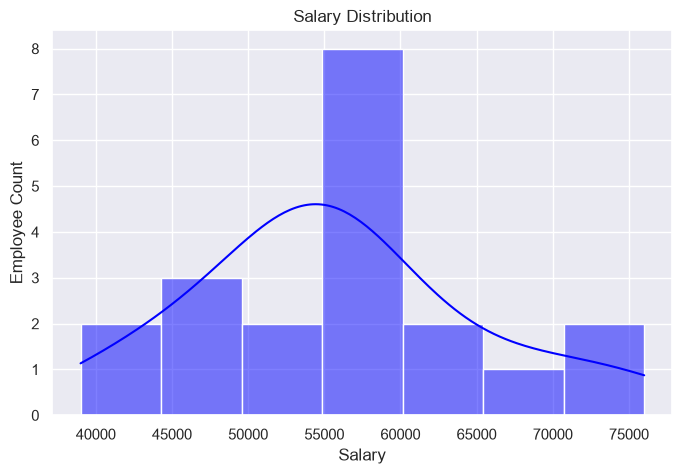

In [31]:
sns.set_theme(palette='deep')
fig, ax=plt.subplots(figsize=(8,5))
sns.histplot(df['salary'], bins=7, kde=True, color='blue', ax=ax)
ax.set(title='Salary Distribution', xlabel="Salary", ylabel="Employee Count")
plt.show()

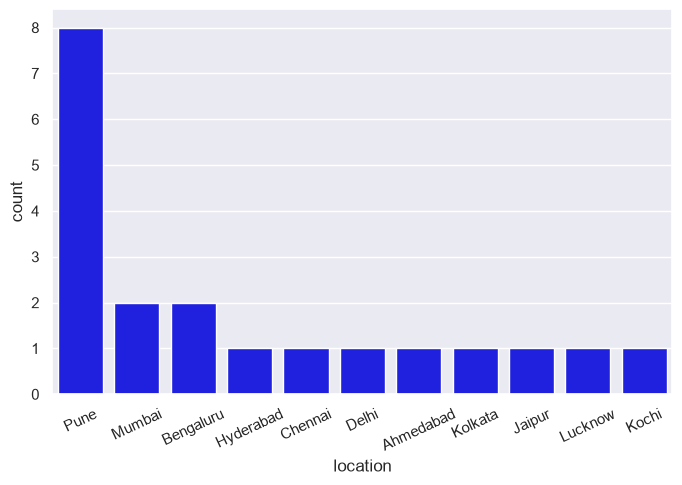

In [33]:
fig, ax = plt.subplots(figsize=(8,5))
sns.countplot(data=df, x="location", color='blue')
plt.xticks(rotation=25)
plt.show()

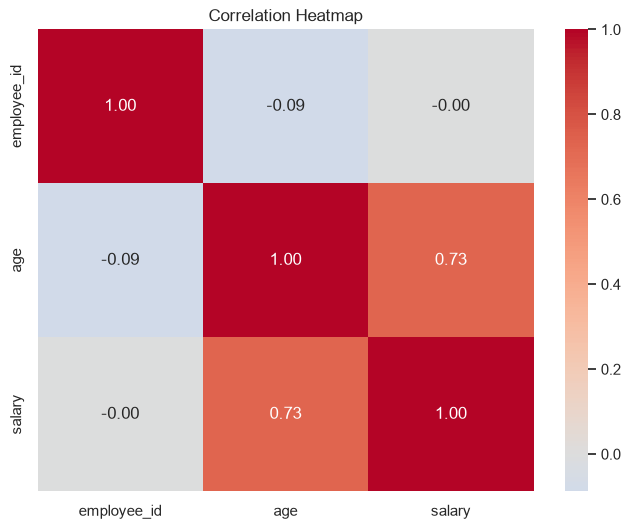

In [39]:
numeric = df.select_dtypes(include="number")
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", center=0, ax=ax, cmap="coolwarm")
ax.set_title("Correlation Heatmap")
plt.show()

In [ ]:
pair_grid